# Bayesian interactive fixed-effects synthetic control

This how-to fits a known-truth panel with `InteractiveFixedEffectsSyntheticControl`. The untreated path is an additive unit intercept, an additive time intercept, and a loading-factor product. Rank is not selected. A multiplicative gamma process shrinks unused factor scales, and the plotted bands marginalize that prior.

These bands are posterior uncertainty for this model. They are not Xu's cross-validated rank interval, and they do not claim nominal coverage.

The model note is [Interactive fixed-effects synthetic control](../knowledgebase/interactive-fixed-effects.md).


In [ ]:
import numpy as np
import pandas as pd

from causalpy.experiments.interactive_fixed_effects import (
    InteractiveFixedEffectsSyntheticControl,
)
from causalpy.tests.known_truth_panels import latent_factor

## Panel and cells that enter the fit

`latent_factor` is an exact rank-2 product plus a planted post-period shift on the treated unit. Control cells at every time, and treated cells strictly before `treatment_time`, are permissible. Treated post-intervention cells are excluded from counterfactual fitting. They are used only when impacts are aligned.


In [ ]:
panel = latent_factor
data = panel.data.copy()
treatment_time = panel.treatment_time
permissible = pd.DataFrame(
    True,
    index=data.index,
    columns=list(panel.control_units) + list(panel.treated_units),
)
permissible.loc[data.index >= treatment_time, list(panel.treated_units)] = False
print("Treated post-intervention cells excluded from fitting:")
print(permissible.loc[data.index >= treatment_time, list(panel.treated_units)])
print("Planted untreated treated path:")
print(panel.untreated["treated"].to_numpy())

Treated post-intervention cells excluded from fitting:
   treated
4    False
5    False
6    False
7    False
Planted untreated treated path:
[ 2. -1.  2. -1.  2. -1.  2. -1.]


## Fit

`max_factors` is an upper bound, not a selected rank. There is no `n_factors` argument. The short sample below is for this notebook, not a coverage study.


In [ ]:
experiment = InteractiveFixedEffectsSyntheticControl(
    data,
    treatment_time,
    panel.control_units,
    panel.treated_units,
    max_factors=4,
)
experiment.build()
experiment.fit(draws=30, tune=40, chains=1, random_seed=11, progressbar=False)
result = experiment.result
print(result.score)
print("shrinkage_state shape", dict(result.shrinkage_state.sizes))

unit_0_r2        0.808229
unit_0_r2_std    0.291714
dtype: float64
shrinkage_state shape {'chain': 1, 'draw': 30, 'factors': 4}


## Observed and training cells

Donor trajectories are the training panel. The treated series is plotted with the post-intervention segment marked as excluded from the factor fit.


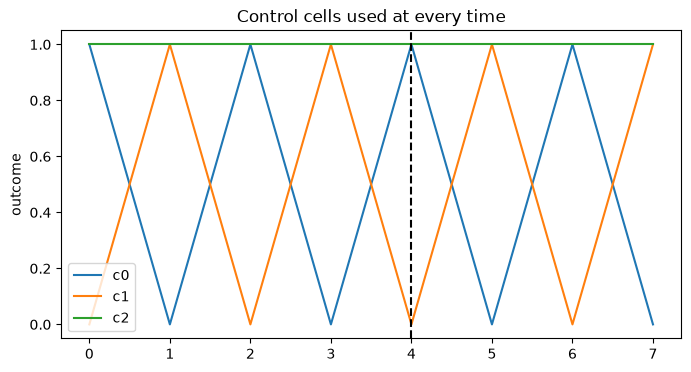

In [ ]:
ax = data[list(panel.control_units)].plot(
    figsize=(8, 4), title="Control cells used at every time"
)
ax.axvline(treatment_time, color="black", linestyle="--")
ax.set_ylabel("outcome")

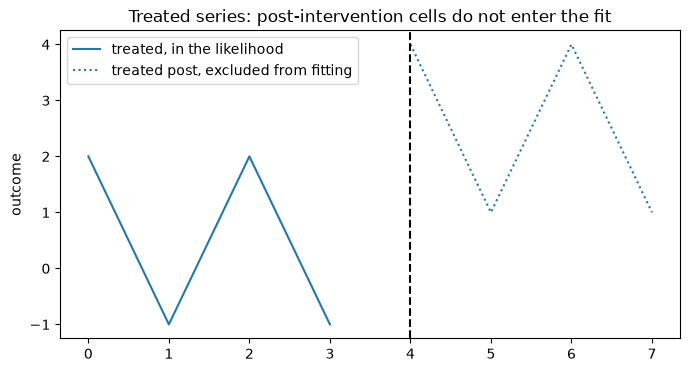

In [ ]:
treated = data["treated"]
pre = treated.loc[treated.index < treatment_time]
post = treated.loc[treated.index >= treatment_time]
ax = pre.plot(figsize=(8, 4), label="treated, in the likelihood", color="C0")
post.plot(ax=ax, label="treated post, excluded from fitting", color="C0", linestyle=":")
ax.axvline(treatment_time, color="black", linestyle="--")
ax.legend()
ax.set_title("Treated series: post-intervention cells do not enter the fit")
ax.set_ylabel("outcome")

## Untreated trajectory and impacts

The figure is the reconstructed trajectory, not the raw factors. Raw factors are not uniquely identified. The dashed line in the interpretation below is the planted untreated path. The band does not claim nominal coverage.


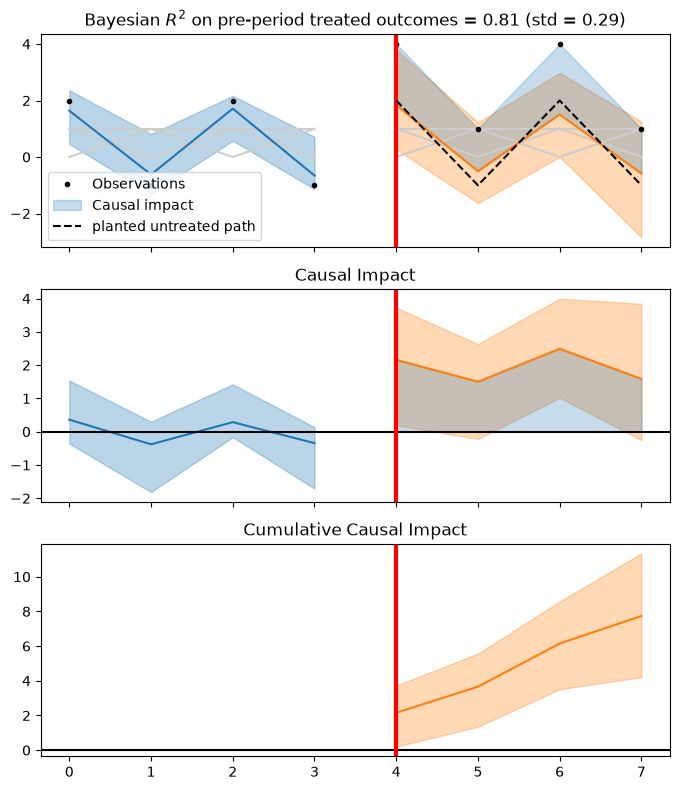

In [ ]:
figure, axes = experiment.plot(show=False, plot_predictors=True)
post_index = data.index[data.index >= treatment_time]
truth = panel.untreated.loc[post_index, "treated"]
axes[0].plot(
    post_index, truth, color="black", linestyle="--", label="planted untreated path"
)
axes[0].legend()
figure.tight_layout()

Point impacts are observed minus the untreated trajectory. Cumulative impact adds those post-period impacts. Both move if the treated post-intervention outcomes change. The trajectory does not.


In [ ]:
shifted = data.copy()
shifted.loc[shifted.index >= treatment_time, "treated"] += 4.0
refit = InteractiveFixedEffectsSyntheticControl(
    shifted,
    treatment_time,
    panel.control_units,
    panel.treated_units,
    max_factors=4,
).fit(draws=30, tune=40, chains=1, random_seed=11, progressbar=False)
same_path = np.allclose(result.predictions_post, refit.result.predictions_post)
impacts_moved = not np.allclose(result.impact_post, refit.result.impact_post)
print("trajectory unchanged after editing treated post outcomes:", same_path)
print("impacts updated:", impacts_moved)

trajectory unchanged after editing treated post outcomes: True
impacts updated: True


## Pre-period holdout

Treat the last pre-period time as if it were already post-intervention. That cell is then excluded from fitting. Compare the posterior mean at that time with the planted untreated outcome. This is a predictive check, not a coverage claim.


In [ ]:
holdout_time = treatment_time - 1
holdout = InteractiveFixedEffectsSyntheticControl(
    data,
    holdout_time,
    panel.control_units,
    panel.treated_units,
    max_factors=4,
).fit(draws=30, tune=40, chains=1, random_seed=13, progressbar=False)
held = holdout.result.predictions_post.mean(("chain", "draw")).sel(
    treated_units="treated", obs_ind=holdout_time
)
planted = float(panel.untreated.loc[holdout_time, "treated"])
print("holdout time", holdout_time, "posterior mean", float(held), "planted", planted)

holdout time 3 posterior mean -0.4852668190863399 planted -1.0


## Shrinkage upper bound

The same panel with a smaller and a larger `max_factors` still returns a marginalized trajectory and one scale per factor. Neither result stores a selected integer rank. The plot is the reconstructed path, not the latent factors.


max_factors=2 shrinkage length 2
max_factors=4 shrinkage length 4
pre-period score {'unit_0_r2': 0.9949982192434336, 'unit_0_r2_std': 0.007812088289792112}


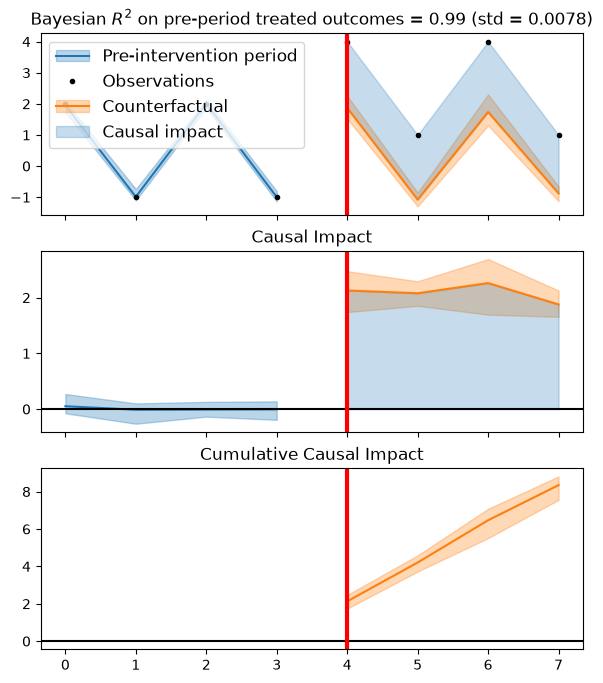

In [ ]:
short = InteractiveFixedEffectsSyntheticControl(
    data,
    treatment_time,
    panel.control_units,
    panel.treated_units,
    max_factors=2,
).fit(draws=20, tune=30, chains=1, random_seed=17, progressbar=False)
print("max_factors=2 shrinkage length", short.result.shrinkage_state.sizes["factors"])
print("max_factors=4 shrinkage length", result.shrinkage_state.sizes["factors"])
short.plot(show=False)
print("pre-period score", short.result.score.to_dict())

## What the posterior does not say

`shrinkage_state` is the per-factor scale the prior can drive toward zero. A small later scale means that factor was shrunk, not that a rank was selected. Xu's classical estimator would report one chosen rank and a different uncertainty statement. This notebook's bands include uncertainty from the shrinkage prior and from the Gaussian observation model. They exclude treated post-intervention outcomes from the fit, and they do not include serial correlation or a claim of nominal coverage.
